#Reconhecimento de imagens utilizando CNN - CIFAR10
Este exemplo utiliza a base de dados CIFAR10, que consiste em um conjunto de imagens pertencentes a 10 categorias.

Fonte: https://keras.io/api/datasets/cifar10/

Importante: Para este exemplo será preciso ativar a GPU para diminuir o tempo de processamento.

Para isso, clique em Editar > Configurações de notebook > GPU.

##Etapa 01
Importar as bibliotecas de aprendizado de máquina e computação científica.

In [1]:
#Bibliotecas de aprendizado de máquina
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import Dropout

#Bibliotecas de computação científica
import numpy as np
import matplotlib.pyplot as plt

##Etapa 02
Importar a base de dados CIFAR10 do Keras

Curiosidade: O Keras fornece um conjunto de base de dados para aprendizado. Veja mais em: https://keras.io/api/datasets/

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 19s 0us/step


##Etapa 03
Conhecer e plotar a base de dados

x_train (50000, 32, 32, 3)
y_train (50000, 1)
x_test (10000, 32, 32, 3)
y_test (10000, 1)
Classes de imagens:  ['avião', 'automóvel', 'pássaro', 'gato', 'veado', 'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']


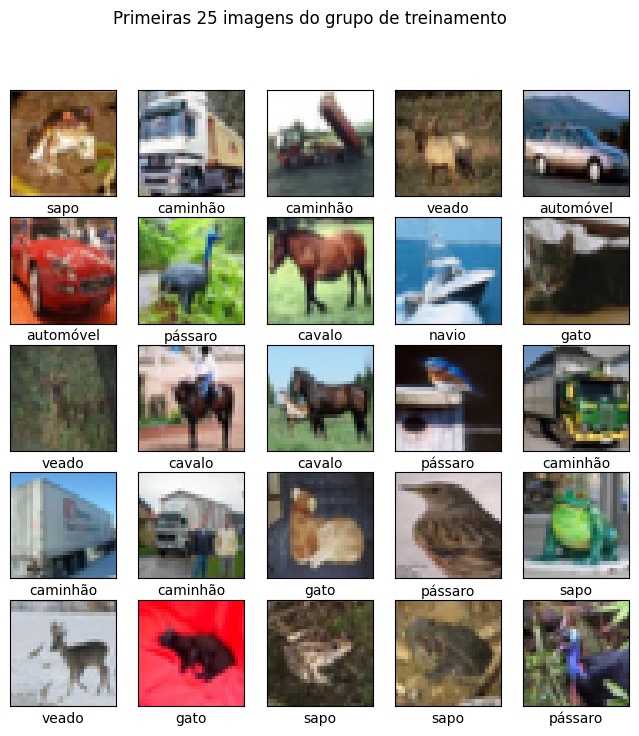

In [3]:
#Nome das categorias:
# Label         Descrição         Tradução
# 0             airplane          avião
# 1             automobile        automóvel
# 2             bird              pássaro
# 3             cat               gato
# 4             deer              veado
# 5             dog               cachorro
# 6             frog              sapo
# 7             horse             cavalo
# 8             ship              navio
# 9             truck             caminhão

#Verificar a quantidade de dados para treinamento e validação
print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)

#Define uma lista com os nomes das categorias
class_names = ['avião', 'automóvel', 'pássaro', 'gato', 'veado',
               'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']

print('Classes de imagens: ', class_names)

#Plotar imagem
plt.figure(figsize=(8,8))
plt.suptitle('Primeiras 25 imagens do grupo de treinamento')
for i in range(25):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(x_train[i])
  plt.xlabel(class_names[y_train[i][0]])
plt.show()

##Etapa 04
Pré-processar as labels para reduzir uma dimensão desnecessária e normalizar as imagens de forma que os valores de intensidade para os pixels fiquem entre 0 e 1.

In [8]:
y_train = np.squeeze(y_train)
y_test = np.squeeze(y_test)

x_train = x_train / 255
x_test = x_test / 255

##Etapa 05
Construir a rede neural utilizando o Keras.

In [ ]:
model = Sequential()
model.add(Conv2D(64, (2,2), activation='relu', input_shape=(32, 32, 3))),
model.add(MaxPooling2D((2,2))),
model.add(Conv2D(16, (2,2), activation='relu')),
model.add(MaxPooling2D((2,2))),
model.add(Dropout(0.25)),
model.add(Flatten()),
model.add(Dense(512, activation='relu')),
model.add(Dropout(0.3)),
model.add(Dense(10, activation='softmax'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 31, 31, 64)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 411,994 (1.57 MB)

 Trainable params: 411,994 (1.57 MB)

 Non-trainable params: 0 (0.00 B)

##Etapa 06
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/


In [ ]:
model.compile(optimizer='SGD',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

##Etapa 07
Treinar o modelo e realizar a validação.

Epoch 1/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.1639 - loss: 2.2424 - val_accuracy: 0.2629 - val_loss: 2.0481
Epoch 2/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.2718 - loss: 1.9973 - val_accuracy: 0.3470 - val_loss: 1.8406
Epoch 3/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.3496 - loss: 1.8051 - val_accuracy: 0.4167 - val_loss: 1.6488
Epoch 4/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.3973 - loss: 1.6689 - val_accuracy: 0.4583 - val_loss: 1.5194
Epoch 5/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4238 - loss: 1.5887 - val_accuracy: 0.4621 - val_loss: 1.5098
Epoch 6/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4419 - loss: 1.5385 - val_accuracy: 0.4965 - val_loss: 1.4188
Epoch 7/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4581 - loss: 1.4989 - val_accuracy: 0.5034 - val_loss: 1.3929
Epoch 8/100
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.4695 - loss:

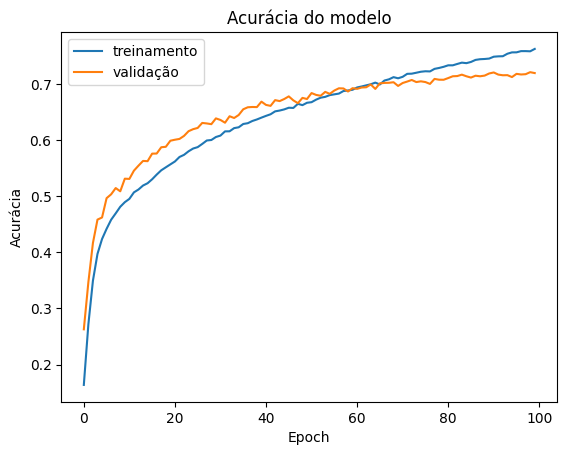

In [ ]:
history = model.fit(x_train, y_train, epochs=200, batch_size=100, validation_data=(x_test, y_test))

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Acurácia do modelo')
plt.ylabel('Acurácia')
plt.xlabel('Epoch')
plt.legend(['treinamento', 'validação'], loc='upper left')
plt.show()

##Etapa 08
Realizar algumas predições. Experimente variar a amostra (variável i)

In [ ]:
y_test.shape

(10000,)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step


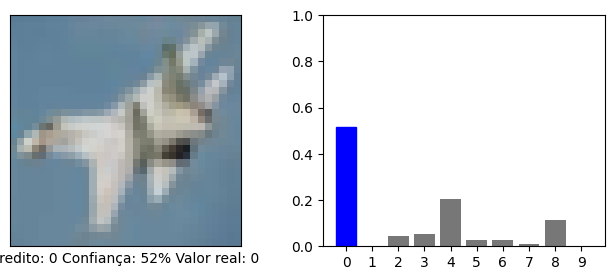

In [ ]:
predictions = model.predict(x_test)
i = 10

def plot_image(prediction_array, true_label, img):
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(img, cmap=plt.cm.binary)
  predicted_label = np.argmax(prediction_array)
  plt.xlabel('Predito: {} Confiança: {:2.0f}% Valor real: {}'.format(predicted_label, 100*np.max(prediction_array), true_label))

def plot_rate(prediction_array, true_label):
  plt.grid(False)
  plt.xticks(range(10))
  thisplot = plt.bar(range(10), prediction_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(prediction_array)
  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')


plt.figure(figsize=(8,3))
plt.subplot(1,2,1)
plot_image(predictions[i], y_test[i], x_test[i])
plt.subplot(1,2,2)
plot_rate(predictions[i], y_test[i])
plt.show()

##Etapa 09
Encontrar todas as predições erradas.

In [ ]:
error_classification = []

for i in range(len(predictions)):
  if (np.argmax(predictions[i]) != y_test[i]):
    error_classification.append(i)

print('Total de predições erradas: ', len(error_classification))
print('Lista das predições erradas: ', error_classification)


Total de predições erradas:  2807
Lista das predições erradas:  [7, 12, 24, 25, 33, 35, 37, 49, 52, 57, 58, 59, 61, 63, 65, 67, 69, 76, 85, 87, 91, 99, 106, 114, 119, 120, 121, 125, 126, 128, 135, 138, 139, 143, 147, 148, 160, 165, 167, 169, 171, 179, 187, 188, 190, 191, 194, 195, 201, 210, 211, 212, 213, 218, 219, 226, 227, 228, 232, 237, 238, 242, 245, 247, 249, 250, 256, 258, 259, 262, 263, 264, 275, 279, 284, 287, 293, 295, 302, 305, 308, 309, 312, 320, 321, 323, 324, 327, 332, 340, 343, 346, 352, 355, 356, 363, 365, 366, 367, 368, 370, 376, 378, 383, 384, 385, 387, 388, 391, 399, 405, 409, 411, 412, 416, 421, 422, 426, 428, 430, 431, 433, 434, 437, 438, 439, 443, 449, 450, 453, 455, 456, 457, 459, 460, 488, 491, 494, 500, 525, 526, 528, 532, 537, 538, 539, 541, 551, 556, 565, 567, 568, 573, 577, 586, 598, 607, 618, 626, 628, 630, 631, 633, 637, 638, 639, 640, 641, 655, 668, 669, 672, 673, 675, 676, 677, 679, 680, 682, 683, 685, 688, 689, 690, 692, 695, 702, 705, 707, 710, 711, 717